# Synodic Playground

In [42]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [43]:
import matplotlib.pyplot as plt
import numpy as np
from astropy.time import Time
from astroquery.jplhorizons import Horizons
from lamberthub import izzo2015
from numpy.linalg import norm
from scipy.integrate import solve_ivp

from cesium.constants import (
    AU_TO_M,
    DAY_TO_SEC,
    DEG_TO_RAD,
    HOUR_TO_SEC,
    KM_TO_M,
    MIN_TO_SEC,
)
from cesium.guidance.interplanetary import flyby_shoot
from cesium.math.base import angle_between
from cesium.math.time import greg_to_jd
from cesium.orbital.ephemeris import planet_elements_and_rv
from cesium.orbital.interplanetary import OrbitalFlyby
from cesium.orbital.transformations import radec_to_cartesian
from cesium.physics.dynamics import two_body, synodic_dynamics
from cesium.plotting import plot_3d, plot_flybys
from cesium.world.constants import (
    MU_EARTH,
    MU_MOON,
    A_MOON,
    R_EARTH,
    R_MOON
)

## Moon shooting

AA 279B homework

### TODO: potential energy and checks

### Propagation

In [44]:
r_bc_earth = MU_MOON / (MU_MOON + MU_EARTH) * A_MOON
r_bc_moon = MU_EARTH / (MU_MOON + MU_EARTH) * A_MOON
w_earth_moon = np.sqrt( (MU_EARTH + MU_MOON) / A_MOON**3)

In [45]:
def earth_moon_synodic_dynamics(t, state):
    del t
    return synodic_dynamics(state, MU_EARTH, MU_MOON, r_bc_earth, r_bc_moon, w_earth_moon)

In [46]:
# Initial conditions
state0 = np.zeros(6)

rho_earth_sat = R_EARTH + 200 * KM_TO_M
phi = 47.60061087 * DEG_TO_RAD
v_inj = 10.92377104 * KM_TO_M

# x,y
state0[0] = -rho_earth_sat*np.cos(phi) - r_bc_earth
state0[1] = -rho_earth_sat*np.sin(phi)

# vx,vy
state0[3] =  v_inj * np.sin(phi)
state0[4] = -v_inj * np.cos(phi)

In [47]:
t_span = (0, 7 * DAY_TO_SEC)
t_arr = np.linspace(t_span[0], t_span[1], 100000)
sol = solve_ivp(earth_moon_synodic_dynamics, t_span, state0, method='LSODA', t_eval=t_arr, rtol=1e-6, atol=1e-9)

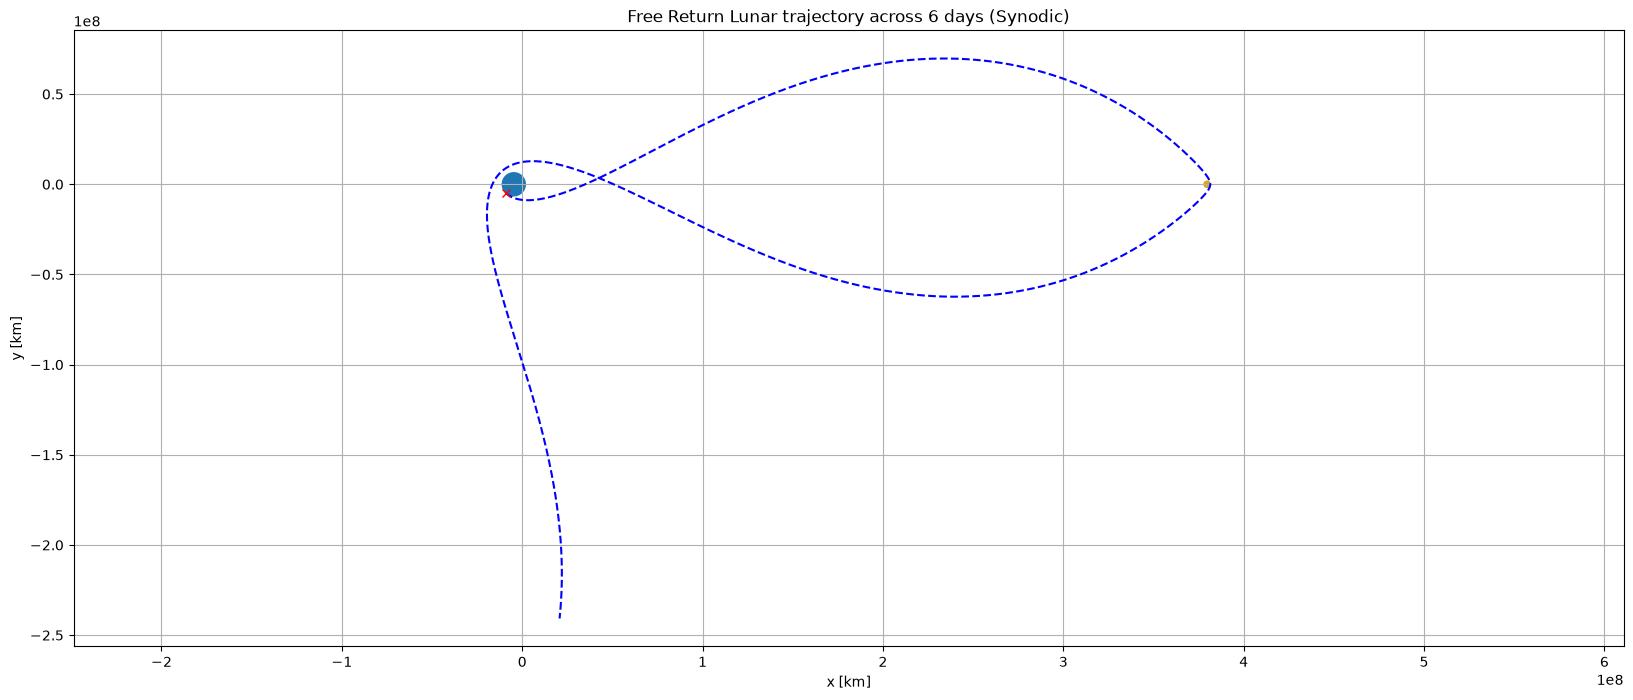

In [48]:
fig, ax = plt.subplots(figsize=(20, 8))
ax.set_title('Free Return Lunar trajectory across 6 days (Synodic)')

# Trajectory
ax.plot(sol.y[0], sol.y[1], 'b--', label='Trajectory')
ax.plot(sol.y[0,0], sol.y[1,0], 'rx', label='Initial position')

# Bodies
# ax.plot(-r_bc_earth, 0, "bo", markersize=5, label="Earth")
# ax.plot(r_bc_moon, 0, "o", color="goldenrod", markersize=5, label="Moon")
ax.add_patch(plt.Circle((-r_bc_earth,0), R_EARTH, color='tab:blue', fill=True))
ax.add_patch(plt.Circle((r_bc_moon,0), R_MOON, color='goldenrod', fill=True))

ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal', adjustable='datalim')

# ax.set_xlim(-r_bc_earth - R_EARTH*1.5, -r_bc_earth + R_EARTH*1.5)
# ax.set_ylim(-R_EARTH*1.5, R_EARTH*1.5)
ax.grid(True)
plt.show()

In [49]:
rs_moon_sat = sol.y[0:3] - np.array([r_bc_moon, 0, 0])[:,None]
r_moon_sat = np.apply_along_axis(np.linalg.norm, 0, rs_moon_sat)

perilune = np.min(r_moon_sat)
t_perilune_day = sol.t[np.argmin(r_moon_sat)] / DAY_TO_SEC

# Different answer and ICs than the homework becasue MU_MOON was different for it
print(f"Perilune ({perilune:.2f}km, {perilune-R_MOON:.2f}km altitude) at {t_perilune_day:.1f} days")

Perilune (1757037.32km, 20037.32km altitude) at 2.9 days
